In [1]:
import numpy as np
import os
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import trange
from scipy.optimize import minimize
from scipy.linalg import orth
from tqdm import trange
import helpers_attractors as h
import importlib
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from scipy.interpolate import CubicSpline, RectBivariateSpline, RegularGridInterpolator
from matplotlib.path import Path
from matplotlib.colors import Normalize
from matplotlib import cm
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
from skimage import measure
import matplotlib.patches as mpatches
from scipy.integrate import solve_ivp

device = "cuda" if torch.cuda.is_available() else "cpu"

# VDP oscillator

We will train an RNN to embed the VDP oscillator, then look at its network decomp.

In [2]:
def vanderpol_vec_torch(x, mu=1.0):
    is_1d = (x.dim() == 1)
    if is_1d:
        x = x.unsqueeze(0)   # (1,2)

    if not torch.is_tensor(mu):
        mu = x.new_tensor(mu)
    else:
        mu = mu.to(dtype=x.dtype, device=x.device)

    x0 = x[:, 0]   # x
    x1 = x[:, 1]   # y

    f0 = x1
    f1 = -x0 + mu * x1 * (1 - x0 * x0)

    out = torch.stack([f0, f1], dim=1)  # (B,2)

    if is_1d:
        return out[0]
    return out

nu = 0.25

In [3]:
class TwoLayerMLP(nn.Module):
    def __init__(self, latent_dim=64, num_noise_sources = 8):
        super().__init__()
        self.Gamma = nn.Linear(2, latent_dim, bias=False)   
        self.input_bias = nn.Parameter(torch.zeros(latent_dim))  
        self.W_s = nn.Linear(latent_dim, 2, bias= False)
        self.I_s = nn.Parameter(torch.zeros(2))
        self.B_s = nn.Parameter(torch.randn(2, num_noise_sources))

    def forward(self, x):
        z = self.Gamma(x) + self.input_bias       
        z = torch.tanh(z)
        out = -x + self.W_s(z) + self.I_s  
        return out

In [4]:
latent_dim = 64
model = TwoLayerMLP(latent_dim).to(device)

opt = optim.Adam(model.parameters(), lr=1e-3)
loss_fn = nn.MSELoss()

n_samples = 25_000
x_train = (torch.rand(n_samples, 2) * 8.0 - 4.0).to(device)
y_train = vanderpol_vec_torch(x_train).to(device)
_eye2 = torch.eye(2, device=device)
D_target = (nu**2) * _eye2  

lambda_diff = 20
epochs = 30_000

for epoch in trange(epochs, desc= 'training MLP'):
    opt.zero_grad()
    
    
    pred = model(x_train)
    
    drift_loss = loss_fn(pred, y_train)

    D_model = model.B_s@(model.B_s.T)
    diffusion_loss = torch.norm(D_model - D_target, p='fro')**2
    
    loss = drift_loss + lambda_diff*diffusion_loss
    loss.backward()
    opt.step()
    
    if (epoch + 1) % 1000 == 0:
        print(f"epoch {epoch+1:4d} loss: {loss.item():.6f} drift: {drift_loss:.6f} diff: {diffusion_loss:.6f}")

training MLP:   4%|▊                      | 1051/30000 [00:03<01:33, 308.22it/s]

epoch 1000 loss: 286.282867 drift: 22.972313 diff: 13.165527


training MLP:   7%|█▌                     | 2042/30000 [00:06<01:40, 278.46it/s]

epoch 2000 loss: 62.973213 drift: 11.831040 diff: 2.557109


training MLP:  10%|██▎                    | 3031/30000 [00:10<01:29, 300.65it/s]

epoch 3000 loss: 20.117161 drift: 6.521142 diff: 0.679801


... (50 outputs left out)

training MLP:  97%|█████████████████████▎| 29053/30000 [01:35<00:03, 310.10it/s]

epoch 29000 loss: 0.000318 drift: 0.000318 diff: 0.000000


training MLP: 100%|██████████████████████| 30000/30000 [01:38<00:00, 304.55it/s]

epoch 30000 loss: 0.000301 drift: 0.000301 diff: 0.000000


In [6]:
print(model.B_s@(model.B_s.T))

Gamma = model.Gamma.weight.detach()
Gamma_pinv = torch.linalg.pinv(Gamma).detach()
b = model.input_bias.detach()
W = Gamma @ model.W_s.weight.detach() 
I = Gamma @ model.I_s.detach() +  b
B = Gamma @ model.B_s.detach()

print(Gamma_pinv@Gamma)

tensor([[6.2416e-02, 8.3475e-05],
        [8.3475e-05, 6.2477e-02]], grad_fn=<MmBackward0>)
tensor([[ 1.0000e+00, -7.7300e-08],
        [-8.9407e-08,  1.0000e+00]])


We want to split our network into two more intelligent components of the form,

$$
W = \Gamma \Omega + \Gamma \Pi,
$$

where $\Gamma \Omega$ is symmetric. This means that both components will still be confined to the manifold. We do this decomposition by finding the matrix,

$$
\text{argmin}_\Omega ||\Gamma \Omega - C||_F^2, \hspace{20pt} \text{subject to } \Gamma\Omega = (\Gamma \Omega)^{\top},
$$
where $C= \frac{1}{2}(W+ W^{\top})$. This problem has a closed form solution,
$$
\Omega^* = \Gamma^{\dagger}C\Gamma \Gamma^{\dagger}.
$$

Note that $\Gamma \Pi$ is asymmetric but not neccessarily antisymmetric.

In [7]:
C = 0.5*(W + W.T)

Omega = Gamma_pinv@C@Gamma@(Gamma_pinv)

W_sym = Gamma@Omega
W_asym = W - W_sym

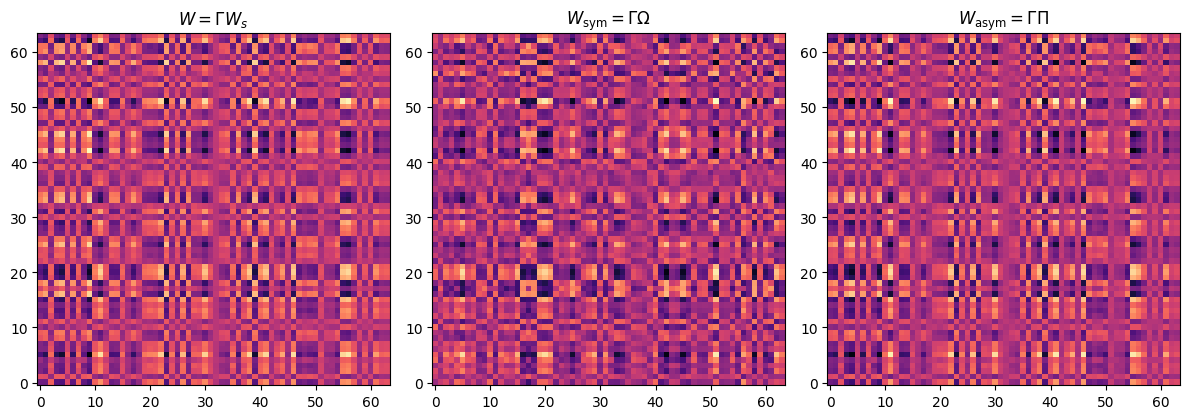

In [8]:
fig, ax = plt.subplots(1,3)
fig.set_size_inches(12,4)

ax[0].imshow(W, origin = 'lower', cmap = 'magma_r')
ax[1].imshow(W_sym, origin = 'lower', cmap = 'magma_r')
ax[2].imshow(W_asym, origin = 'lower', cmap = 'magma_r')

ax[0].set_title(r'$W= \Gamma W_s$')
ax[1].set_title(r'$W_{\text{sym}}= \Gamma \Omega$')
ax[2].set_title(r'$W_{\text{asym}}= \Gamma \Pi$')

for a in ax:
    a.set_aspect('equal')

plt.tight_layout()
plt.show()

In [9]:
def project_rnn_vector_field(y, W, I, Gamma, Gamma_pinv, b):
    device = W.device
    dtype = W.dtype
    y = torch.as_tensor(y, dtype=dtype, device=device)

    squeeze_out = False
    if y.dim() == 1:
        y = y.unsqueeze(0)
        squeeze_out = True
    elif y.dim() != 2:
        raise ValueError(f"y must be 1D or 2D tensor, got shape {tuple(y.shape)}")

    b = torch.as_tensor(b, dtype=dtype, device=device).reshape(1, -1)
    I = torch.as_tensor(I, dtype=dtype, device=device).reshape(1, -1)

    u = y.matmul(Gamma.T) + b

    g = -u + torch.tanh(u).matmul(W.T) + I

    result = g.matmul(Gamma_pinv.T)

    if squeeze_out:
        return result.squeeze(0)
    return result  

def project_asymm_vector_field(y, W, I, Gamma, Gamma_pinv, b):
    device = W.device
    dtype = W.dtype
    y = torch.as_tensor(y, dtype=dtype, device=device)

    squeeze_out = False
    if y.dim() == 1:
        y = y.unsqueeze(0)
        squeeze_out = True
    elif y.dim() != 2:
        raise ValueError(f"y must be 1D or 2D tensor, got shape {tuple(y.shape)}")

    b = torch.as_tensor(b, dtype=dtype, device=device).reshape(1, -1)
    I = torch.as_tensor(I, dtype=dtype, device=device).reshape(1, -1)

    u = y.matmul(Gamma.T) + b

    g = torch.tanh(u).matmul(W.T)

    result = g.matmul(Gamma_pinv.T)

    if squeeze_out:
        return result.squeeze(0)
    return result  

def integrate_rnn(W, I, B, dt, T, u0):

    latent_dim = W.shape[0]
    num_noise_sources = B.shape[1]
    Nt = int(T/dt)
    
    u = torch.zeros((latent_dim,Nt))
    u[:, 0] = u0

    for t in trange(0,Nt-1):
        u_ = u[:, t]
        u[:, t+1] = u_ + dt*(-u_ + W@torch.tanh(u_) + I) + np.sqrt(dt)*B@torch.randn((num_noise_sources,))

    return u

def project_rnn(u, Gamma, b, Gamma_pinv):
    return Gamma_pinv@((u.T - b).T)

def proj(u):
    return project_rnn(u, Gamma, b, Gamma_pinv)

In [10]:
y0 = torch.tensor([-2.0, 0.0], dtype=torch.float32, device=Gamma.device)

dt = 0.01; T = 400; u0 = Gamma @ y0 + b; Nt = int(T/dt)

u = integrate_rnn(W, I, B, dt, T, u0)

y = project_rnn(u, Gamma, b, Gamma_pinv)

100%|██████████████████████████████████| 39999/39999 [00:00<00:00, 55833.64it/s]


In [11]:
y0 = torch.tensor([2.0, 0.0], dtype=torch.float32, device=Gamma.device)

dt = 0.01; T = 400; u0 = Gamma @ y0 + b; Nt = int(T/dt)

u_sym = integrate_rnn(W_sym, I, B, dt, T, u0)

y_sym = project_rnn(u_sym, Gamma, b, Gamma_pinv)

100%|██████████████████████████████████| 39999/39999 [00:00<00:00, 55580.80it/s]


In [12]:
grid_lim = 6; grid_res = 15
xs = torch.linspace(-grid_lim, grid_lim, grid_res)
ys = torch.linspace(-grid_lim, grid_lim, grid_res)

X, Y = torch.meshgrid(xs, ys, indexing="xy")
grid_points = torch.stack([X.flatten(), Y.flatten()], dim=-1).to(device)

with torch.no_grad():
    F_full = project_rnn_vector_field(grid_points, W, I, Gamma, Gamma_pinv, b).cpu()
    F_symm = project_rnn_vector_field(grid_points, W_sym, I, Gamma, Gamma_pinv, b).cpu()
    f_anti = project_asymm_vector_field(grid_points, W_asym, I, Gamma, Gamma_pinv, b).cpu()

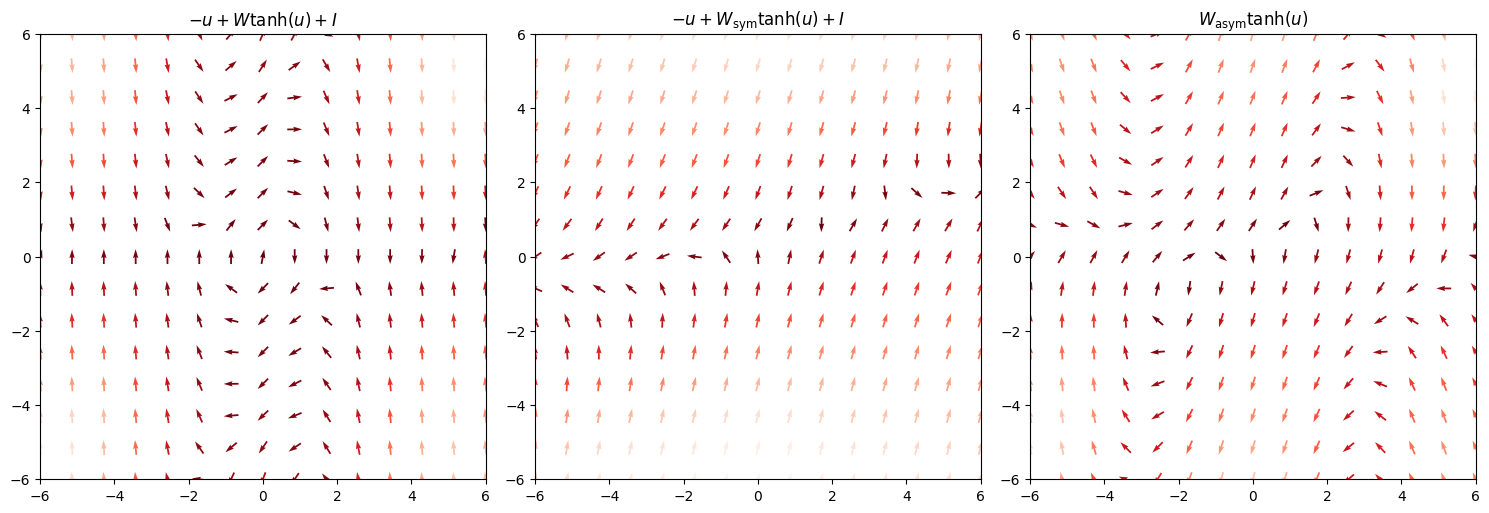

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(15,5))


X, Y = torch.meshgrid(xs, ys, indexing="xy")
grid_points = torch.stack([X.flatten(), Y.flatten()], dim=-1).to(device)
Xn, Yn = X.cpu().numpy(), Y.cpu().numpy()

def plot_quiver(ax, F, title=None):
    U = F[:, 0].reshape(grid_res, grid_res).cpu().numpy()
    V = F[:, 1].reshape(grid_res, grid_res).cpu().numpy()
    M = np.sqrt(U**2 + V**2) + 1e-8  # magnitude
    U_n = U / M
    V_n = V / M

    q = ax.quiver(
        Xn, Yn, U_n, V_n, M,
        cmap='Reds_r', scale=30, pivot='middle'
    )
    ax.set_title(title)

plot_quiver(ax[0], F_full, r"$-u + W \tanh(u) + I$")
plot_quiver(ax[1], F_symm, r"$-u + W_{\text{sym}} \tanh(u) + I$")
plot_quiver(ax[2], f_anti, r"$W_{\text{asym}} \tanh(u)$")

for a in ax:
    a.set_xlim(-grid_lim, grid_lim)
    a.set_ylim(-grid_lim, grid_lim)
    a.set_aspect('equal')

plt.tight_layout()
plt.show()

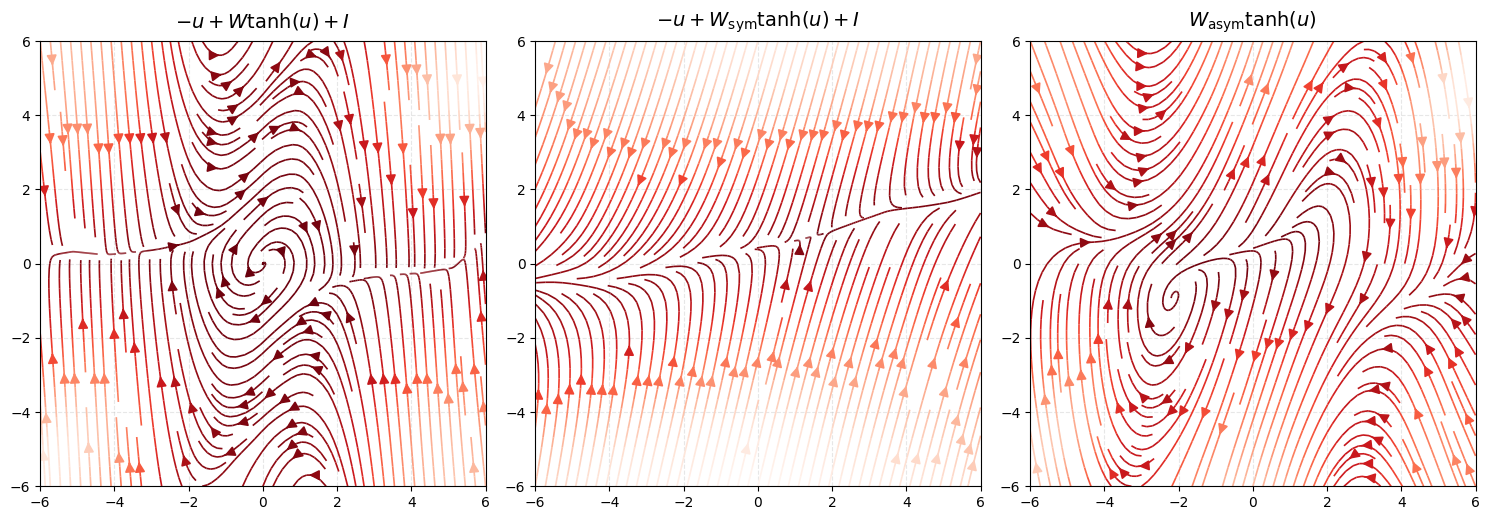

In [15]:
fig, ax = plt.subplots(1, 3, figsize=(15, 5))

X, Y = torch.meshgrid(xs, ys, indexing="xy")
grid_points = torch.stack([X.flatten(), Y.flatten()], dim=-1).to(device)
Xn, Yn = X.cpu().numpy(), Y.cpu().numpy()

def plot_stream(ax, F, title=None):
    U = F[:, 0].reshape(grid_res, grid_res).cpu().numpy()
    V = F[:, 1].reshape(grid_res, grid_res).cpu().numpy()
    M = np.sqrt(U**2 + V**2) + 1e-8 

    strm = ax.streamplot(
        Xn, Yn, U, V,
        color=M,
        cmap='Reds_r',   
        density=1.5,     
        linewidth=1.2,    
        arrowsize=1.5    
    )
    
    ax.set_title(title, fontsize=14, pad=10)
    return strm

plot_stream(ax[0], F_full, r"$-u + W \tanh(u) + I$")
plot_stream(ax[1], F_symm, r"$-u + W_{\text{sym}} \tanh(u) + I$")
plot_stream(ax[2], f_anti, r"$W_{\text{asym}} \tanh(u)$")

for a in ax:
    a.set_xlim(-grid_lim, grid_lim)
    a.set_ylim(-grid_lim, grid_lim)
    a.set_aspect('equal')
    a.grid(True, alpha=0.3, linestyle='--')

plt.tight_layout()
plt.show()

In [16]:
def energy_function_rnn_2d(y, W, I, Gamma, Gamma_pinv, b, eps=1e-6, promote_dtype=torch.float64):
    device = W.device
    dtype = promote_dtype
    y = torch.as_tensor(y, device=device, dtype=dtype)
    W = torch.as_tensor(W, device=device, dtype=dtype)
    I = torch.as_tensor(I, device=device, dtype=dtype)
    Gamma = torch.as_tensor(Gamma, device=device, dtype=dtype)
    Gamma_pinv = torch.as_tensor(Gamma_pinv, device=device, dtype=dtype)
    b = torch.as_tensor(b, device=device, dtype=dtype)
    

    for name, t in (("y", y), ("W", W), ("I", I), ("Gamma", Gamma), ("Gamma_pinv", Gamma_pinv), ("b", b)):
        if not torch.isfinite(t).all():
            raise ValueError(f"Input tensor {name} contains NaN or Inf (max {t.abs().max().item():.3g}).")

    squeeze_out = False
    if y.dim() == 1:
        y = y.unsqueeze(0)
        squeeze_out = True
    elif y.dim() != 2:
        raise ValueError(f"y must be 1D or 2D tensor, got shape {tuple(y.shape)}")

    b = b.reshape(1, -1)
    I = I.reshape(1, -1)

    u = y.matmul(Gamma.T) + b    
    v = torch.tanh(u)            

    v = torch.tanh(u)
    v_clamped = v.clamp(-1+eps, 1-eps)
    atanh_v = 0.5*(torch.log1p(v_clamped) - torch.log1p(-v_clamped))
    log_term = 0.5 * torch.log1p(-v_clamped*v_clamped)
    integral = torch.sum(v_clamped * atanh_v + log_term, dim=1)
    quad = 0.5 * torch.einsum('bi,ij,bj->b', v_clamped, W, v_clamped)

    lin = torch.sum(I * v_clamped, dim=1)


    E = -quad - lin + integral  
    if not torch.isfinite(E).all():
        nan_mask = ~torch.isfinite(E)
        raise RuntimeError(
            "Energy contains NaN/Inf after computation. "
            f"clamp_eps={clamp_eps}. Max |v| = {v.abs().max().item():.6g}. "
            f"First offending batch indices: {torch.nonzero(nan_mask)[:10].squeeze().tolist()}"
        )

    if squeeze_out:
        return E.squeeze(0)
    return E

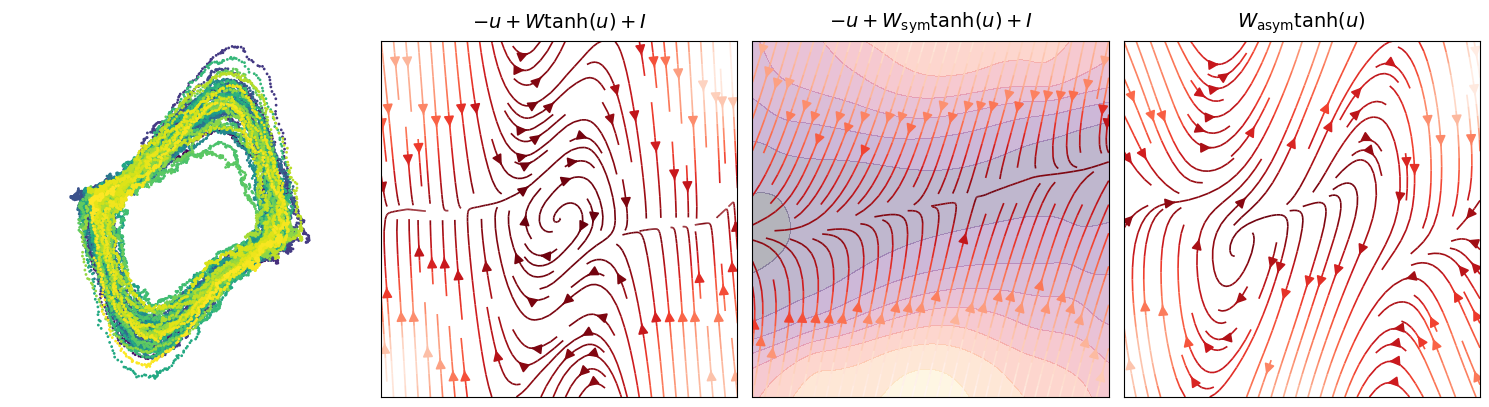

In [27]:
fig, ax = plt.subplots(1, 4, figsize=(15,5))

grid_lim = 6; grid_res = 200
xs1 = torch.linspace(-grid_lim, grid_lim, grid_res)
ys1 = torch.linspace(-grid_lim, grid_lim, grid_res)
X, Y = torch.meshgrid(xs1, ys1, indexing="xy")
grid_points = torch.stack([X.flatten(), Y.flatten()], dim=-1).to(device)
E = energy_function_rnn_2d(grid_points, W_sym, I, Gamma, Gamma_pinv, b)
E = E.reshape(grid_res,grid_res)

ax[2].contourf(X, Y, E, levels=10, cmap='magma', alpha = 0.3)

X, Y = torch.meshgrid(xs, ys, indexing="xy")
grid_points = torch.stack([X.flatten(), Y.flatten()], dim=-1).to(device)
Xn, Yn = X.cpu().numpy(), Y.cpu().numpy()
grid_res = 15

def plot_stream(ax, F, title=None):
    U = F[:, 0].reshape(grid_res, grid_res).cpu().numpy()
    V = F[:, 1].reshape(grid_res, grid_res).cpu().numpy()
    M = np.sqrt(U**2 + V**2) + 1e-8  # Magnitude for coloring


    strm = ax.streamplot(
        Xn, Yn, U, V,
        color=M,
        cmap='Reds_r',   
        density=1,      
        linewidth=1.2,    
        arrowsize=1.5     
    )
    
    ax.set_title(title, fontsize=14, pad=10)
    return strm

plot_stream(ax[1], F_full, r"$-u + W \tanh(u) + I$")
plot_stream(ax[2], F_symm, r"$-u + W_{\text{sym}} \tanh(u) + I$")
plot_stream(ax[3], f_anti, r"$W_{\text{asym}} \tanh(u)$")

time = np.linspace(0,T,int(T/dt))
ds = 1
ax[0].scatter(y[0,::ds], y[1,::ds], c=time[::ds], cmap='viridis', s=1, rasterized=True)

for a in ax:
    a.set_xlim(-grid_lim, grid_lim)
    a.set_ylim(-grid_lim, grid_lim)
    a.set_aspect('equal')
    a.set_xticks([])
    a.set_yticks([])


ax[0].set_xlim(-grid_lim/1.5, grid_lim/1.5)
ax[0].set_ylim(-grid_lim/1.5, grid_lim/1.5)
sns.despine(left = True, bottom = True, ax = ax[0])

plt.tight_layout()
plt.show()

# Lorenz attractor

In [28]:
def lorenz_vec_torch(x, sigma = 10, rho = 28, beta = 8/3):
    is_1d = (x.dim() == 1)
    if is_1d:
        x = x.unsqueeze(0)   # (1,2)

    x0 = x[:, 0]   # x
    x1 = x[:, 1]   # y
    x2 = x[:, 2]   # z

    f0 = sigma*(x1 - x0)
    f1 = x0*(rho-x2)-x1
    f2 = x0*x1 - beta*x2

    out = torch.stack([f0, f1, f2], dim=1)  # (B,2)

    if is_1d:
        return out[0]
    return out

In [141]:
class TwoLayerMLP(nn.Module):
    def __init__(self, latent_dim=64, num_noise_sources = 8, proj_dim = 2):
        super().__init__()
        self.Gamma = nn.Linear(proj_dim, latent_dim, bias=False)   
        self.input_bias = nn.Parameter(torch.zeros(latent_dim))  
        self.W_s = nn.Linear(latent_dim, proj_dim, bias= False)
        self.I_s = nn.Parameter(torch.zeros(proj_dim))
        self.B_s = nn.Parameter(torch.randn(proj_dim, num_noise_sources))

    def forward(self, x):
        z = self.Gamma(x) + self.input_bias       
        z = torch.tanh(z)
        out = -x + self.W_s(z) + self.I_s  
        return out

In [142]:
latent_dim = 512
model = TwoLayerMLP(latent_dim, proj_dim = 3).to(device)

params = torch.load('lorenz_rnn.pt', weights_only=False)

W = torch.tensor(params['W'])
Gamma = torch.tensor(params['Gamma'])
I = torch.tensor(params['I'])
B = torch.tensor(params['B'])
b = torch.tensor(params['b'])
Gamma_pinv = torch.tensor(params['Gamma_pinv'])

with torch.no_grad():
    model.Gamma.weight.copy_(Gamma)
    model.W_s.weight.copy_(Gamma_pinv@W)
    model.I_s.copy_(Gamma_pinv@(I-b))
    model.B_s.copy_(Gamma_pinv@B)
    model.input_bias.copy_(b)

In [143]:
C = 0.5*(W + W.T)

Omega = Gamma_pinv@C@Gamma@(Gamma_pinv)

W_sym = Gamma@Omega
W_asym = W - W_sym

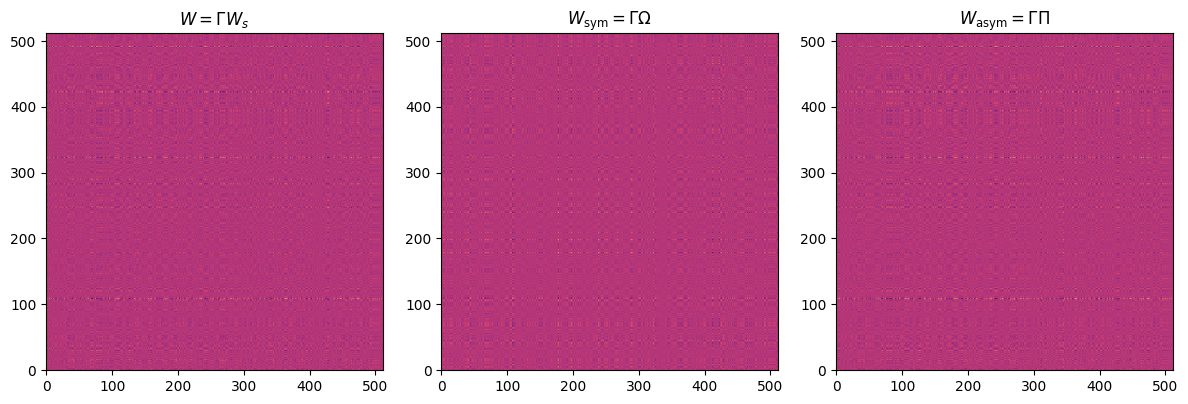

In [144]:
fig, ax = plt.subplots(1,3)
fig.set_size_inches(12,4)

ax[0].imshow(W, origin = 'lower', cmap = 'magma_r')
ax[1].imshow(W_sym, origin = 'lower', cmap = 'magma_r')
ax[2].imshow(W_asym, origin = 'lower', cmap = 'magma_r')

ax[0].set_title(r'$W= \Gamma W_s$')
ax[1].set_title(r'$W_{\text{sym}}= \Gamma \Omega$')
ax[2].set_title(r'$W_{\text{asym}}= \Gamma \Pi$')

for a in ax:
    a.set_aspect('equal')

plt.tight_layout()
plt.show()

In [145]:
grid_lim = 25; grid_res = 10
xs = torch.linspace(-grid_lim, grid_lim, grid_res)
ys = torch.linspace(-grid_lim, grid_lim, grid_res)
zs = torch.linspace(0, 50, grid_res)

X, Y, Z = torch.meshgrid(xs, ys, zs, indexing='xy')
grid_points = torch.stack([X.flatten(), Y.flatten(), Z.flatten()], dim=-1).to(device)

with torch.no_grad():
    F_full = project_rnn_vector_field(grid_points, W, I, Gamma, Gamma_pinv, b).cpu()
    F_symm = project_rnn_vector_field(grid_points, W_sym, I, Gamma, Gamma_pinv, b).cpu()
    f_anti = project_asymm_vector_field(grid_points, W_asym, I, Gamma, Gamma_pinv, b).cpu()

In [146]:
y0 = torch.tensor([0.0, 0.0, 0.0], dtype=torch.float32, device=Gamma.device)

dt = 0.0001; T = 100; u0 = Gamma @ y0 + b; Nt = int(T/dt)

u = integrate_rnn(W, I, B, dt, T, u0)

y = project_rnn(u, Gamma, b, Gamma_pinv)
time = np.linspace(0,T,int(T/dt))

100%|████████████████████████████████| 999999/999999 [00:34<00:00, 28913.66it/s]


/var/folders/j3/3jf2wkbj5756yfdv4zjq5j300000gn/T/ipykernel_3166/4146110445.py:25: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  mag = np.sqrt(U**2 + V**2 + W**2)
/var/folders/j3/3jf2wkbj5756yfdv4zjq5j300000gn/T/ipykernel_3166/4146110445.py:28: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  U_unit = U / safe_mag
/var/folders/j3/3jf2wkbj5756yfdv4zjq5j300000gn/T/ipykernel_3166/4146110445.py:29: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  V_unit = V / safe_mag
/var/folders/j3/3jf2wkbj5756yfdv4zjq5j300000gn/T/ipykernel_3166/4146110445.py:30: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  W_unit = W / safe_mag
/var/folders/j3/3jf2

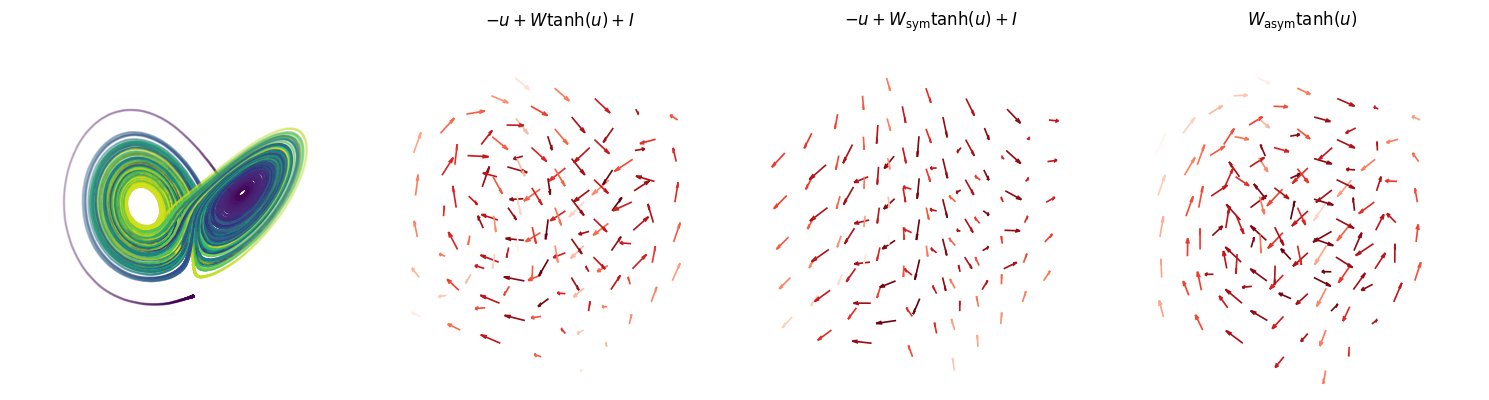

In [148]:
arrow_length = 5.0   
subsample = 2         
cmap_name = 'Reds_r'

fig = plt.figure(figsize=(15,8))
ax0 = fig.add_subplot(141, projection='3d')
ax = fig.add_subplot(142, projection='3d')
ax1 = fig.add_subplot(143, projection='3d')
ax2 = fig.add_subplot(144, projection='3d')
ax0.scatter(y[0,::ds], y[1,::ds], y[2,::ds], c=time[::ds], cmap='viridis', s=1, rasterized=True, alpha = 0.1)

axes = [ax, ax1, ax2, ax0]
forces = [F_full, F_symm, f_anti]

for i, axs in enumerate(axes):

    if i < 3:
        F = forces[i]
        U = F[:, 0].reshape(grid_res, grid_res, grid_res)
        V = F[:, 1].reshape(grid_res, grid_res, grid_res)
        W = F[:, 2].reshape(grid_res, grid_res, grid_res)
        
        Xn = X.numpy(); Yn = Y.numpy(); Zn = Z.numpy()
        
        mag = np.sqrt(U**2 + V**2 + W**2)
        
        safe_mag = np.where(mag == 0, 1.0, mag)
        U_unit = U / safe_mag
        V_unit = V / safe_mag
        W_unit = W / safe_mag
        
        U_plot = U_unit * arrow_length
        V_plot = V_unit * arrow_length
        W_plot = W_unit * arrow_length
        
        s = subsample
        Xs = Xn[::s, ::s, ::s].flatten()
        Ys = Yn[::s, ::s, ::s].flatten()
        Zs = Zn[::s, ::s, ::s].flatten()
        
        Us = U_plot[::s, ::s, ::s].flatten()
        Vs = V_plot[::s, ::s, ::s].flatten()
        Ws = W_plot[::s, ::s, ::s].flatten()
        
        Mags = mag[::s, ::s, ::s].flatten()
        
        norm = Normalize(vmin=Mags.min(), vmax=Mags.max())
        cmap = cm.get_cmap(cmap_name)
        colors = cmap(norm(Mags))
        
        axs.quiver(Xs, Ys, Zs, Us, Vs, Ws, length=1.0, normalize=False, colors=colors, linewidths=1.2)
    
    axs.set_xlim(-grid_lim, grid_lim)
    axs.set_ylim(-grid_lim, grid_lim)
    axs.set_zlim(zs.min(), zs.max())
    
    axs.set_xlabel('x'); ax.set_ylabel('y'); ax.set_zlabel('z')
    axs.set_box_aspect((2*grid_lim, 2*grid_lim, zs.max()-zs.min()))
    
    axs.xaxis.pane.fill = False
    axs.yaxis.pane.fill = False
    axs.zaxis.pane.fill = False
    
    axs.set_axis_off()          
    axs.grid(False) 

ds = 5

ax.set_title(r"$-u + W \tanh(u) + I$")
ax1.set_title(r"$-u + W_{\text{sym}} \tanh(u) + I$")
ax2.set_title(r"$W_{\text{asym}} \tanh(u)$")

sns.despine()
plt.tight_layout()
plt.show()

In [88]:
grid_lim = 25; grid_res = 10
xs = torch.linspace(-grid_lim, grid_lim, grid_res)
ys = torch.linspace(-grid_lim, grid_lim, grid_res)
zs = torch.linspace(0, 50, grid_res)

X, Y, Z = torch.meshgrid(xs, ys, zs, indexing='xy')
grid_points = torch.stack([X.flatten(), Y.flatten(), Z.flatten()], dim=-1).to(device)

E = energy_function_rnn_2d(grid_points, W_sym, I, Gamma, Gamma_pinv, b)
E = E.reshape(grid_res, grid_res, grid_res)

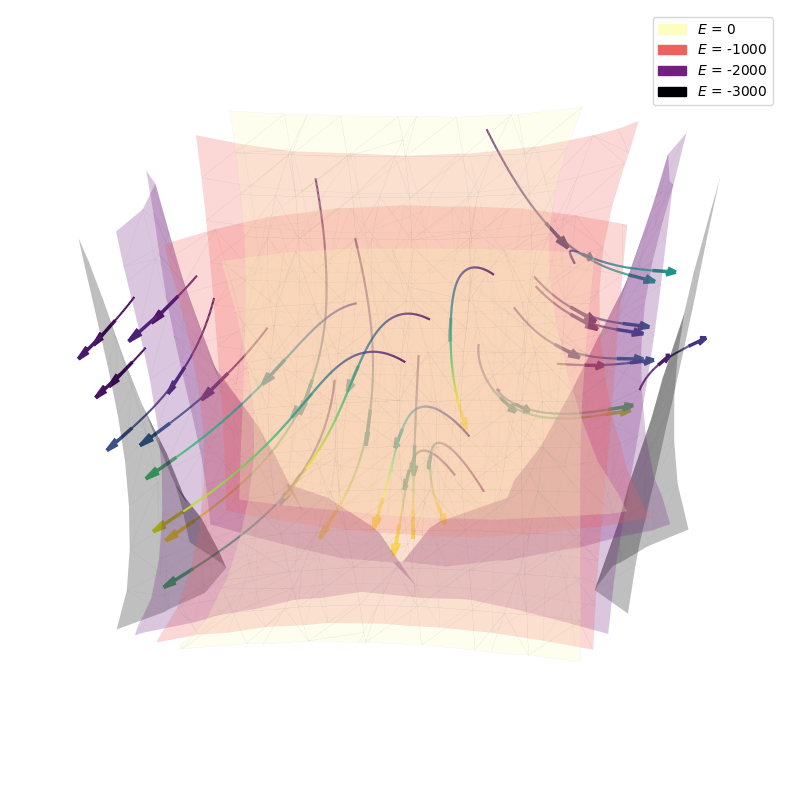

In [128]:
nx, ny, nz = E_np.shape
x = np.linspace(-grid_lim, grid_lim, grid_res)   
y = np.linspace(-grid_lim, grid_lim, grid_res)
z = np.linspace(0, 50, grid_res)

levels = [0, -1000, -2000, -3000]   

fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')

legend_handles = [] 


for i, level in enumerate(levels):
    verts, faces, normals, values = measure.marching_cubes(
        E_np, level=level, spacing=(x[1]-x[0], y[1]-y[0], z[1]-z[0])
    )
    
    verts[:, 0] += x[0]
    verts[:, 1] += y[0]
    verts[:, 2] += z[0]
    
    mesh = verts[faces]
    poly = Poly3DCollection(mesh, alpha=0.25, linewidths=0.1)
    
    c = plt.cm.magma_r(i / max(1, len(levels)-1))
    
    poly.set_facecolor(c)
    poly.set_edgecolor('grey')
    ax.add_collection3d(poly)
    
    patch = mpatches.Patch(color=c, label=fr'$E$ = {level}')
    legend_handles.append(patch)


U = F_symm[:, 0].reshape(grid_res, grid_res, grid_res).detach().cpu().numpy()
V = F_symm[:, 1].reshape(grid_res, grid_res, grid_res).detach().cpu().numpy()
W = F_symm[:, 2].reshape(grid_res, grid_res, grid_res).detach().cpu().numpy()

interp_U = RegularGridInterpolator((y, x, z), U, bounds_error=False, fill_value=0)
interp_V = RegularGridInterpolator((y, x, z), V, bounds_error=False, fill_value=0)
interp_W = RegularGridInterpolator((y, x, z), W, bounds_error=False, fill_value=0)

def vector_field(t, p):
    pt = [p[1], p[0], p[2]]
    return [interp_U(pt)[0], interp_V(pt)[0], interp_W(pt)[0]]


num_seeds = 25
seeds_x = np.random.uniform(-grid_lim, grid_lim, num_seeds)
seeds_y = np.random.uniform(-grid_lim, grid_lim, num_seeds)
seeds_z = np.random.uniform(z.max() * 0.5, z.max(), num_seeds) 

t_span = (0, 0.4)  
t_eval = np.linspace(0, 0.4, 500)

norm = plt.Normalize(t_eval.min(), t_eval.max())

for i in range(num_seeds):
    p0 = [seeds_x[i], seeds_y[i], seeds_z[i]]
    sol = solve_ivp(vector_field, t_span, p0, t_eval=t_eval, max_step=0.5)
    
    if sol.success and len(sol.t) > 1:
        x_raw, y_raw, z_raw = sol.y
        t_raw = sol.t
        
        z_max_val = z.max()
        in_bounds = (np.abs(x_raw) <= grid_lim) & (np.abs(y_raw) <= grid_lim) & (z_raw >= 0) & (z_raw <= z_max_val)
        
        if not np.all(in_bounds):
            exit_idx = np.argmin(in_bounds) 
            
            if exit_idx < 2:
                continue
                
            x_sol = x_raw[:exit_idx]
            y_sol = y_raw[:exit_idx]
            z_sol = z_raw[:exit_idx]
            t_sol = t_raw[:exit_idx]
        else:
            x_sol, y_sol, z_sol, t_sol = x_raw, y_raw, z_raw, t_raw
            
        points = np.array([x_sol, y_sol, z_sol]).T.reshape(-1, 1, 3)
        segments = np.concatenate([points[:-1], points[1:]], axis=1)
        
        lc = Line3DCollection(segments, cmap='viridis', norm=norm, alpha=1.0)
        lc.set_array(t_sol[:-1])
        lc.set_linewidth(1.5)
        ax.add_collection3d(lc)
        

        mid_idx = len(x_sol) // 2
        mid_pt = [x_sol[mid_idx], y_sol[mid_idx], z_sol[mid_idx]]
        
        dx_mid, dy_mid, dz_mid = vector_field(t_sol[mid_idx], mid_pt)
        mid_color = [cm.viridis(norm(t_sol[mid_idx]))]
        
        ax.quiver(mid_pt[0], mid_pt[1], mid_pt[2], 
                  dx_mid, dy_mid, dz_mid, 
                  color=mid_color, length=4.0, normalize=True, 
                  arrow_length_ratio=0.4, linewidths=2.5)

        final_pt = [x_sol[-1], y_sol[-1], z_sol[-1]]
        
        dx_end, dy_end, dz_end = vector_field(t_sol[-1], final_pt)
        end_color = [cm.viridis(norm(t_sol[-1]))]
        
        ax.quiver(final_pt[0], final_pt[1], final_pt[2], 
                  dx_end, dy_end, dz_end, 
                  color=end_color, length=4.0, normalize=True, 
                  arrow_length_ratio=0.4, linewidths=2.5)

ax.set_xlim(x.min(), x.max())
ax.set_ylim(y.min(), y.max())
ax.set_zlim(z.min(), z.max())

ax.set_box_aspect((2*grid_lim, 2*grid_lim, z.max()-z.min()))

ax.xaxis.pane.fill = False
ax.yaxis.pane.fill = False
ax.zaxis.pane.fill = False
ax.set_axis_off()
ax.grid(False)

ax.legend(handles=legend_handles, loc='upper right')

plt.tight_layout()

plt.show()

# Dadras attractor

In [129]:
latent_dim = 1024
model = TwoLayerMLP(latent_dim, proj_dim = 3).to(device)

params = torch.load('dadras_rnn.pt', weights_only=False)

W = torch.tensor(params['W'])
Gamma = torch.tensor(params['Gamma'])
I = torch.tensor(params['I'])
B = torch.tensor(params['B'])
b = torch.tensor(params['b'])
Gamma_pinv = torch.tensor(params['Gamma_pinv'])

with torch.no_grad():
    model.Gamma.weight.copy_(Gamma)
    model.W_s.weight.copy_(Gamma_pinv@W)
    model.I_s.copy_(Gamma_pinv@(I-b))
    model.B_s.copy_(Gamma_pinv@B)
    model.input_bias.copy_(b)

/var/folders/j3/3jf2wkbj5756yfdv4zjq5j300000gn/T/ipykernel_3166/1271835202.py:6: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  W = torch.tensor(params['W'])
/var/folders/j3/3jf2wkbj5756yfdv4zjq5j300000gn/T/ipykernel_3166/1271835202.py:7: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  Gamma = torch.tensor(params['Gamma'])
/var/folders/j3/3jf2wkbj5756yfdv4zjq5j300000gn/T/ipykernel_3166/1271835202.py:8: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  I = torch.tensor(params['I'])
/var/folders/j3/3jf2wkbj5756yfdv4zjq5j300000gn/T/ipykernel_3166/1

In [130]:
y0 = torch.tensor([1.0, 1.0, 0.0], dtype=torch.float32)

dt = 0.0001; T = 100; u0 = Gamma @ y0 + b; Nt = int(T/dt)

u = integrate_rnn(W, I, B, dt, T, u0)

y = project_rnn(u, Gamma, b, Gamma_pinv)

100%|████████████████████████████████| 999999/999999 [00:54<00:00, 18184.94it/s]


In [131]:
C = 0.5*(W + W.T)

Omega = Gamma_pinv@C@Gamma@(Gamma_pinv)

W_sym = Gamma@Omega
W_asym = W - W_sym

In [132]:
grid_lim = 10; grid_res = 10
xs = torch.linspace(-15, 15, grid_res)
ys = torch.linspace(-10, 10, grid_res)
zs = torch.linspace(-15, 15, grid_res)

X, Y, Z = torch.meshgrid(xs, ys, zs, indexing='xy')
grid_points = torch.stack([X.flatten(), Y.flatten(), Z.flatten()], dim=-1).to(device)

with torch.no_grad():
    F_full = project_rnn_vector_field(grid_points, W, I, Gamma, Gamma_pinv, b).cpu()
    F_symm = project_rnn_vector_field(grid_points, W_sym, I, Gamma, Gamma_pinv, b).cpu()
    f_anti = project_asymm_vector_field(grid_points, W_asym, I, Gamma, Gamma_pinv, b).cpu()

/var/folders/j3/3jf2wkbj5756yfdv4zjq5j300000gn/T/ipykernel_3166/1433593924.py:25: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  mag = np.sqrt(U**2 + V**2 + W**2)
/var/folders/j3/3jf2wkbj5756yfdv4zjq5j300000gn/T/ipykernel_3166/1433593924.py:28: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  U_unit = U / safe_mag
/var/folders/j3/3jf2wkbj5756yfdv4zjq5j300000gn/T/ipykernel_3166/1433593924.py:29: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  V_unit = V / safe_mag
/var/folders/j3/3jf2wkbj5756yfdv4zjq5j300000gn/T/ipykernel_3166/1433593924.py:30: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  W_unit = W / safe_mag
/var/folders/j3/3jf2

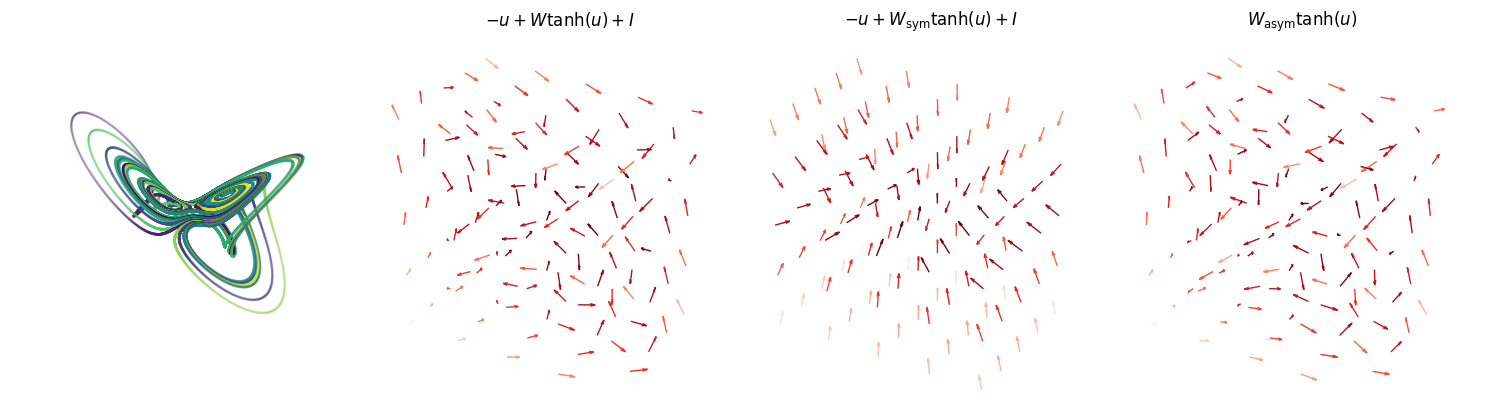

In [133]:
arrow_length = 4.0   
subsample = 2         
cmap_name = 'Reds_r'

fig = plt.figure(figsize=(15,8))
ax0 = fig.add_subplot(141, projection='3d')
ax = fig.add_subplot(142, projection='3d')
ax1 = fig.add_subplot(143, projection='3d')
ax2 = fig.add_subplot(144, projection='3d')
ax0.scatter(y[0,::ds], y[1,::ds], y[2,::ds], c=time[::ds], cmap='viridis', s=1, rasterized=True, alpha = 0.1)

axes = [ax, ax1, ax2, ax0]
forces = [F_full, F_symm, f_anti]

for i, axs in enumerate(axes):

    if i < 3:
        F = forces[i]
        U = F[:, 0].reshape(grid_res, grid_res, grid_res)
        V = F[:, 1].reshape(grid_res, grid_res, grid_res)
        W = F[:, 2].reshape(grid_res, grid_res, grid_res)
        
        Xn = X.numpy(); Yn = Y.numpy(); Zn = Z.numpy()
        
        mag = np.sqrt(U**2 + V**2 + W**2)
        
        safe_mag = np.where(mag == 0, 1.0, mag)
        U_unit = U / safe_mag
        V_unit = V / safe_mag
        W_unit = W / safe_mag
        
        U_plot = U_unit * arrow_length
        V_plot = V_unit * arrow_length
        W_plot = W_unit * arrow_length
        
        s = subsample
        Xs = Xn[::s, ::s, ::s].flatten()
        Ys = Yn[::s, ::s, ::s].flatten()
        Zs = Zn[::s, ::s, ::s].flatten()
        
        Us = U_plot[::s, ::s, ::s].flatten()
        Vs = V_plot[::s, ::s, ::s].flatten()
        Ws = W_plot[::s, ::s, ::s].flatten()
        
        Mags = mag[::s, ::s, ::s].flatten()
        
        norm = Normalize(vmin=Mags.min(), vmax=Mags.max())
        cmap = cm.get_cmap(cmap_name)
        colors = cmap(norm(Mags))
        
        axs.quiver(Xs, Ys, Zs, Us, Vs, Ws, length=0.5, normalize=False, colors=colors, linewidths=1.0)
    
    axs.set_xlim(-grid_lim, grid_lim)
    axs.set_ylim(-grid_lim, grid_lim)
    axs.set_zlim(zs.min(), zs.max())
    
    axs.set_xlabel('x'); ax.set_ylabel('y'); ax.set_zlabel('z')
    axs.set_box_aspect((2*grid_lim, 2*grid_lim, zs.max()-zs.min()))
    
    axs.xaxis.pane.fill = False
    axs.yaxis.pane.fill = False
    axs.zaxis.pane.fill = False
    
    axs.set_axis_off()          
    axs.grid(False) 

ds = 5

ax.set_title(r"$-u + W \tanh(u) + I$")
ax1.set_title(r"$-u + W_{\text{sym}} \tanh(u) + I$")
ax2.set_title(r"$W_{\text{asym}} \tanh(u)$")

sns.despine()
plt.tight_layout()
plt.show()

In [134]:
grid_lim = 15; grid_res = 10
xs = torch.linspace(-15, 15, grid_res)
ys = torch.linspace(-10, 10, grid_res)
zs = torch.linspace(-15, 15, grid_res)

X, Y, Z = torch.meshgrid(xs, ys, zs, indexing='xy')
grid_points = torch.stack([X.flatten(), Y.flatten(), Z.flatten()], dim=-1).to(device)

E = energy_function_rnn_2d(grid_points, W_sym, I, Gamma, Gamma_pinv, b)
E = E.reshape(grid_res, grid_res, grid_res)

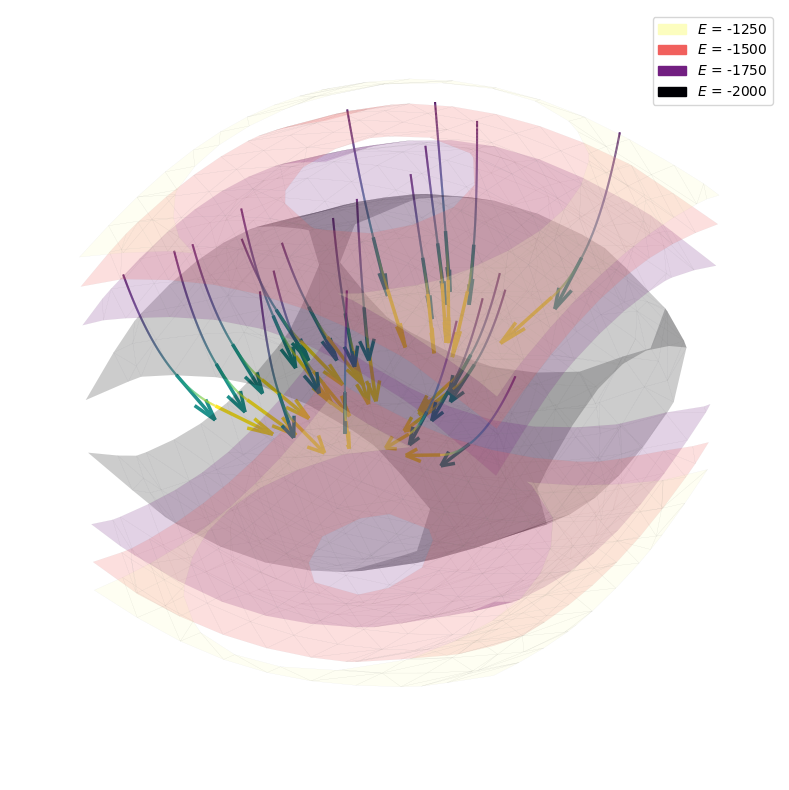

In [140]:
nx, ny, nz = E_np.shape
x = np.linspace(-15, 15, grid_res)   
y = np.linspace(-10, 10, grid_res)
z = np.linspace(-15, 15, grid_res)

levels = [-1250, -1500, -1750, -2000]   

fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')

legend_handles = [] 


for i, level in enumerate(levels):
    verts, faces, normals, values = measure.marching_cubes(
        E_np, level=level, spacing=(x[1]-x[0], y[1]-y[0], z[1]-z[0])
    )
    
    verts[:, 0] += x[0]
    verts[:, 1] += y[0]
    verts[:, 2] += z[0]
    
    mesh = verts[faces]
    poly = Poly3DCollection(mesh, alpha=0.2, linewidths=0.1)
    
    c = plt.cm.magma_r(i / max(1, len(levels)-1))
    
    poly.set_facecolor(c)
    poly.set_edgecolor('grey')
    ax.add_collection3d(poly)
    
    patch = mpatches.Patch(color=c, label=fr'$E$ = {level}')
    legend_handles.append(patch)


U = F_symm[:, 0].reshape(grid_res, grid_res, grid_res).detach().cpu().numpy()
V = F_symm[:, 1].reshape(grid_res, grid_res, grid_res).detach().cpu().numpy()
W = F_symm[:, 2].reshape(grid_res, grid_res, grid_res).detach().cpu().numpy()

interp_U = RegularGridInterpolator((y, x, z), U, bounds_error=False, fill_value=0)
interp_V = RegularGridInterpolator((y, x, z), V, bounds_error=False, fill_value=0)
interp_W = RegularGridInterpolator((y, x, z), W, bounds_error=False, fill_value=0)

def vector_field(t, p):
    pt = [p[1], p[0], p[2]]
    return [interp_U(pt)[0], interp_V(pt)[0], interp_W(pt)[0]]


num_seeds = 25
seeds_x = np.random.uniform(-grid_lim, grid_lim, num_seeds)
seeds_y = np.random.uniform(-grid_lim, grid_lim, num_seeds)
seeds_z = np.random.uniform(z.max() * 0.5, z.max(), num_seeds) 

t_span = (0, 0.4)  
t_eval = np.linspace(0, 0.4, 500)

norm = plt.Normalize(t_eval.min(), t_eval.max())

for i in range(num_seeds):
    p0 = [seeds_x[i], seeds_y[i], seeds_z[i]]
    sol = solve_ivp(vector_field, t_span, p0, t_eval=t_eval, max_step=0.5)
    
    if sol.success and len(sol.t) > 1:
        x_raw, y_raw, z_raw = sol.y
        t_raw = sol.t
        
        z_max_val = z.max()
        in_bounds = (np.abs(x_raw) <= grid_lim) & (np.abs(y_raw) <= grid_lim) & (z_raw >= 0) & (z_raw <= z_max_val)
        
        if not np.all(in_bounds):
            exit_idx = np.argmin(in_bounds) 
            
            if exit_idx < 2:
                continue
                
            x_sol = x_raw[:exit_idx]
            y_sol = y_raw[:exit_idx]
            z_sol = z_raw[:exit_idx]
            t_sol = t_raw[:exit_idx]
        else:
            x_sol, y_sol, z_sol, t_sol = x_raw, y_raw, z_raw, t_raw
            
        points = np.array([x_sol, y_sol, z_sol]).T.reshape(-1, 1, 3)
        segments = np.concatenate([points[:-1], points[1:]], axis=1)
        
        lc = Line3DCollection(segments, cmap='viridis', norm=norm, alpha=1.0)
        lc.set_array(t_sol[:-1])
        lc.set_linewidth(1.5)
        ax.add_collection3d(lc)
        

        mid_idx = len(x_sol) // 2
        mid_pt = [x_sol[mid_idx], y_sol[mid_idx], z_sol[mid_idx]]
        
        dx_mid, dy_mid, dz_mid = vector_field(t_sol[mid_idx], mid_pt)
        mid_color = [cm.viridis(norm(t_sol[mid_idx]))]
        
        ax.quiver(mid_pt[0], mid_pt[1], mid_pt[2], 
                  dx_mid, dy_mid, dz_mid, 
                  color=mid_color, length=4.0, normalize=True, 
                  arrow_length_ratio=0.4, linewidths=2.5)

        final_pt = [x_sol[-1], y_sol[-1], z_sol[-1]]
        
        dx_end, dy_end, dz_end = vector_field(t_sol[-1], final_pt)
        end_color = [cm.viridis(norm(t_sol[-1]))]
        
        ax.quiver(final_pt[0], final_pt[1], final_pt[2], 
                  dx_end, dy_end, dz_end, 
                  color=end_color, length=4.0, normalize=True, 
                  arrow_length_ratio=0.4, linewidths=2.5)

ax.set_xlim(x.min(), x.max())
ax.set_ylim(y.min(), y.max())
ax.set_zlim(z.min(), z.max())

ax.set_box_aspect((2*grid_lim, 2*grid_lim, z.max()-z.min()))

ax.xaxis.pane.fill = False
ax.yaxis.pane.fill = False
ax.zaxis.pane.fill = False
ax.set_axis_off()
ax.grid(False)

ax.legend(handles=legend_handles, loc='upper right')

plt.tight_layout()

plt.show()